<a href="https://colab.research.google.com/github/Perez124/Article-Preview/blob/main/Copy_of_Oct_'26_Week_Day_ML_Final_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

CUSTOMER CHURN PREDICTION SYSTEM

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
df = pd.read_csv('/content/drive/MyDrive/DATASET/customer_churn_dataset.csv')
df.head()

,customer_id,tenure_months,monthly_charges,total_charges,contract_type,internet_service,tech_support,streaming_service,payment_method,paperless_billing,satisfaction_score,num_support_tickets,churn
0,CUST_00001,52,117.30,6120.94,Two year,Fiber optic,1,1,Electronic check,1,5.0,1,0
1,CUST_00002,15,78.44,1048.46,Month-to-month,Fiber optic,1,1,Bank transfer,0,1.0,5,0
2,CUST_00003,61,69.29,4274.02,One year,DSL,1,0,Electronic check,1,1.0,2,0
3,CUST_00004,21,82.29,1633.70,Month-to-month,Fiber optic,0,1,Bank transfer,1,3.0,1,0
4,CUST_00005,24,57.00,1427.48,Month-to-month,DSL,0,1,Electronic check,1,1.0,1,0


Checking Data Structure and Types

In [ ]:
#checking for dupolicates
df.duplicated().sum()

np.int64(0)

In [ ]:
df.shape

(5000, 13)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 13 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   customer_id          5000 non-null   object 
 1   tenure_months        5000 non-null   int64  
 2   monthly_charges      5000 non-null   float64
 3   total_charges        4900 non-null   float64
 4   contract_type        5000 non-null   object 
 5   internet_service     5000 non-null   object 
 6   tech_support         5000 non-null   int64  
 7   streaming_service    5000 non-null   int64  
 8   payment_method       5000 non-null   object 
 9   paperless_billing    5000 non-null   int64  
 10  satisfaction_score   4900 non-null   float64
 11  num_support_tickets  5000 non-null   int64  
 12  churn                5000 non-null   int64  
dtypes: float64(3), int64(6), object(4)
memory usage: 507.9+ KB


In [ ]:
df.describe()

,tenure_months,monthly_charges,total_charges,tech_support,streaming_service,paperless_billing,satisfaction_score,num_support_tickets,churn
count,5000.000000,5000.000000,4900.000000,5000.000000,5000.000000,5000.000000,4900.000000,5000.00000,5000.000000
mean,35.850800,75.958838,2681.932949,0.404200,0.511600,0.689000,3.005714,1.50300,0.230600
std,20.326839,29.468495,1855.736804,0.490786,0.499915,0.462949,1.414058,1.41322,0.421259
min,1.000000,20.000000,-79.200000,0.000000,0.000000,0.000000,1.000000,0.00000,0.000000
25%,18.000000,56.140000,1157.517500,0.000000,0.000000,0.000000,2.000000,0.00000,0.000000
50%,36.000000,75.465000,2360.545000,0.000000,1.000000,1.000000,3.000000,1.00000,0.000000
75%,54.000000,95.140000,3928.410000,1.000000,1.000000,1.000000,4.000000,2.00000,0.000000
max,71.000000,346.020000,8380.400000,1.000000,1.000000,1.000000,5.000000,9.00000,1.000000


Missing values

In [ ]:
df.isna().sum()

,0
customer_id,0
tenure_months,0
monthly_charges,0
total_charges,100
contract_type,0
internet_service,0
tech_support,0
streaming_service,0
payment_method,0
paperless_billing,0


Fixing missing values in total charges column

In [ ]:
#Reaplace blanks with nan
df['total_charges'] = df['total_charges'].replace(' ', np.nan)

In [ ]:
#Replace negative values with nan
df.loc[df['total_charges'] < 0, 'total_charges'] = np.nan

In [ ]:
#Missing values
df['total_charges'].isna().sum()

np.int64(113)

<Axes: >

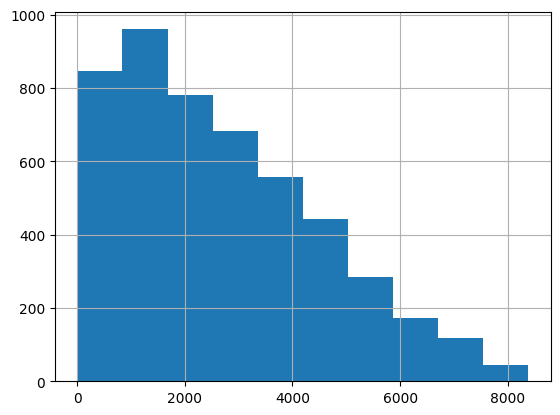

In [ ]:
#Check the distribution of total charges
df['total_charges'].hist()

In [ ]:
#Since the distribution is skewed, we replace the missing values with median
df['total_charges'] = df['total_charges'].fillna(df['total_charges'].median())

In [ ]:
df['total_charges'].isna().sum()

np.int64(0)

Fixing Satisfaction score column

<Axes: >

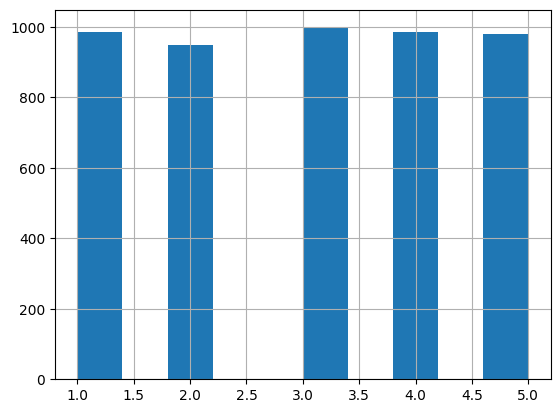

In [ ]:
df['satisfaction_score'].hist()

In [ ]:
#Replace missing values with median
df['satisfaction_score'] = df['satisfaction_score'].fillna(df['satisfaction_score'].median())

In [ ]:
df.isna().sum()

,0
customer_id,0
tenure_months,0
monthly_charges,0
total_charges,0
contract_type,0
internet_service,0
tech_support,0
streaming_service,0
payment_method,0
paperless_billing,0


Fixing Data Types

In [ ]:
#Convert categorical columns
cat_cols = ['contract_type', 'internet_service', 'payment_method']
for col in cat_cols:
  df[col] = df[col].astype('category')

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 13 columns):
 #   Column               Non-Null Count  Dtype   
---  ------               --------------  -----   
 0   customer_id          5000 non-null   object  
 1   tenure_months        5000 non-null   int64   
 2   monthly_charges      5000 non-null   float64 
 3   total_charges        5000 non-null   float64 
 4   contract_type        5000 non-null   category
 5   internet_service     5000 non-null   category
 6   tech_support         5000 non-null   int64   
 7   streaming_service    5000 non-null   int64   
 8   payment_method       5000 non-null   category
 9   paperless_billing    5000 non-null   int64   
 10  satisfaction_score   5000 non-null   float64 
 11  num_support_tickets  5000 non-null   int64   
 12  churn                5000 non-null   int64   
dtypes: category(3), float64(3), int64(6), object(1)
memory usage: 405.9+ KB


EDA

In [ ]:
#Churn Analysis
df['churn'].value_counts(normalize = True)

,proportion
churn,
0,0.7694
1,0.2306


Text(0, 0.5, 'Count')

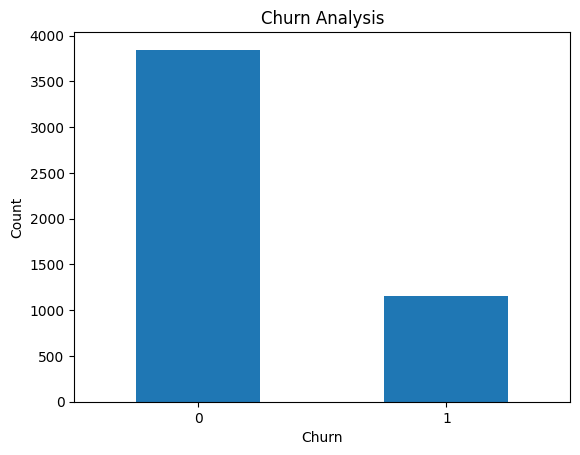

In [ ]:
df['churn'].value_counts().plot(kind = 'bar')
plt.title('Churn Analysis')
plt.xticks(rotation = 0)
plt.xlabel('Churn')
plt.ylabel('Count')

Numerical Features vs Churn

In [ ]:
df.groupby('churn')[[
    'monthly_charges',
    'total_charges',
    'tenure_months',
    'satisfaction_score',
    'num_support_tickets'
]].mean()

,monthly_charges,total_charges,tenure_months,satisfaction_score,num_support_tickets
churn,,,,,
0,73.358342,2703.481009,37.395893,3.174942,1.357941
1,84.635429,2610.039705,30.695577,2.440590,1.986990


Categorical Features vs churn

In [ ]:
#Contract Type
pd.crosstab(df['contract_type'], df['churn'], normalize = 'index')

churn,0,1
contract_type,,
Month-to-month,0.725437,0.274563
One year,0.829641,0.170359
Two year,0.841446,0.158554


<Axes: xlabel='contract_type', ylabel='count'>

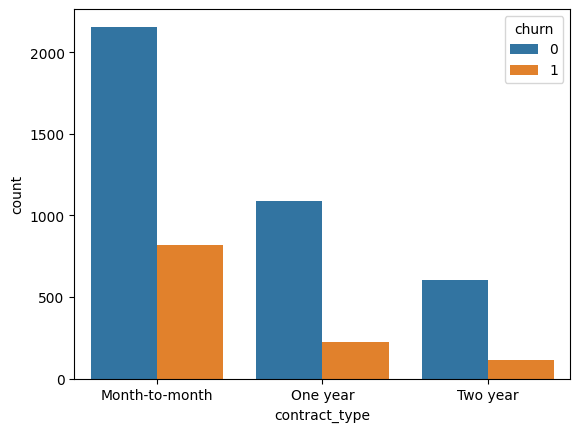

In [ ]:
sns.countplot(x = 'contract_type', hue = 'churn', data = df)

In [ ]:
#Internet service
pd.crosstab(df['internet_service'], df['churn'], normalize = 'index')

churn,0,1
internet_service,,
DSL,0.841470,0.158530
Fiber optic,0.694708,0.305292
No,0.864865,0.135135


<Axes: xlabel='internet_service', ylabel='count'>

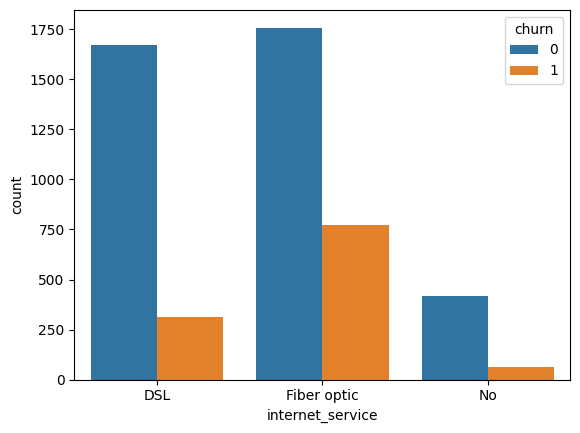

In [ ]:
sns.countplot(x = 'internet_service', hue = 'churn', data = df)

In [ ]:
#Payment Method
pd.crosstab(df['payment_method'], df['churn'], normalize = 'index')

churn,0,1
payment_method,,
Bank transfer,0.777417,0.222583
Credit card,0.779715,0.220285
Electronic check,0.764419,0.235581
Mailed check,0.756270,0.243730


<Axes: xlabel='payment_method', ylabel='count'>

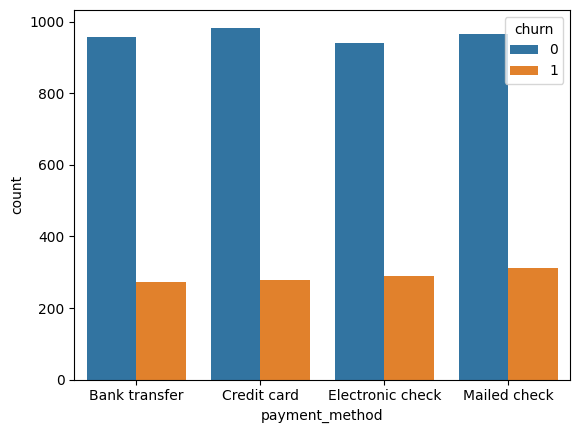

In [ ]:
sns.countplot(x = 'payment_method', hue = 'churn', data = df)

Binary features vs Churn

In [ ]:
#tech support
pd.crosstab(df['tech_support'], df['churn'], normalize = 'index')

churn,0,1
tech_support,,
0,0.718026,0.281974
1,0.845126,0.154874


<Axes: xlabel='tech_support', ylabel='count'>

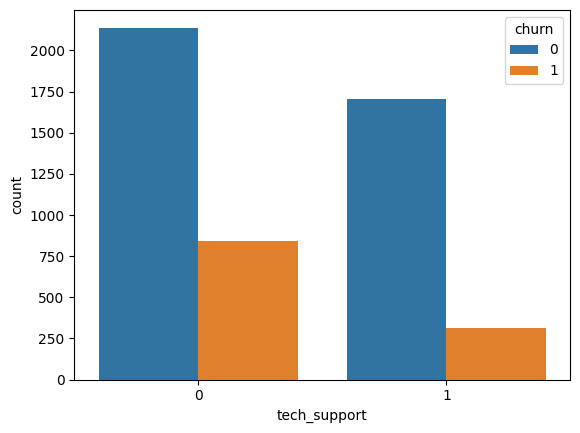

In [ ]:
sns.countplot(x = 'tech_support', hue = 'churn', data = df)

In [ ]:
#streamong service
pd.crosstab(df['streaming_service'], df['churn'], normalize = 'index')

churn,0,1
streaming_service,,
0,0.764128,0.235872
1,0.774433,0.225567


<Axes: xlabel='streaming_service', ylabel='count'>

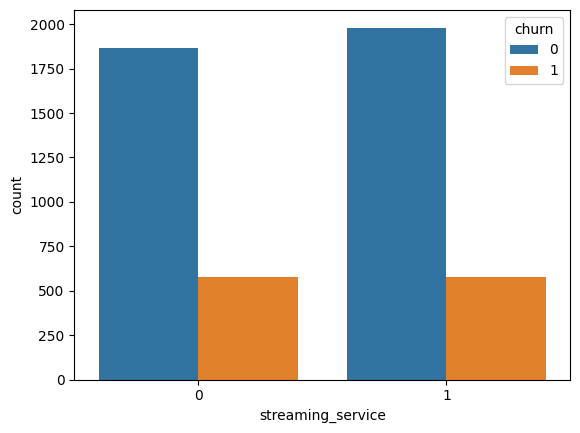

In [ ]:
sns.countplot(x = 'streaming_service', hue = 'churn', data = df)

In [ ]:
#paperless billing
pd.crosstab(df['paperless_billing'], df['churn'], normalize = 'index')

churn,0,1
paperless_billing,,
0,0.778135,0.221865
1,0.765457,0.234543


<Axes: xlabel='paperless_billing', ylabel='count'>

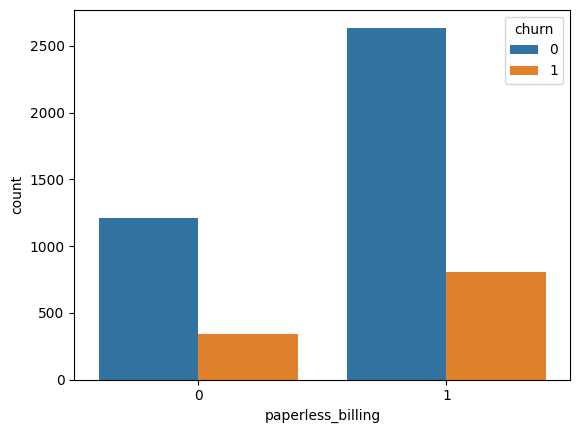

In [ ]:
sns.countplot(x = 'paperless_billing', hue = 'churn', data = df)

Feature Engineering

In [ ]:
#Customer lifetime value
df['avg_monthly_value'] = df['total_charges'] / df['tenure_months']

In [ ]:
#Charge per ticket
df['charges_per_ticket'] = df['monthly_charges'] / (df['num_support_tickets'] + 1)

In [ ]:
#Engagement score
df['engagement_score'] = (
    df['tenure_months'] * 0.4 +
    df['satisfaction_score'] * 0.3 -
    df['num_support_tickets'] * 0.3
 )

In [ ]:
#High risk customer flag
df['high_risk'] =(
    (df['satisfaction_score'] <= 2) &
    (df['num_support_tickets'] >= 3)
 ).astype(int)

In [ ]:
#Tenure Segmentation.
def tenure_group(x):
  if x <= 6:
    return 'new'
  elif x <= 36:
    return 'mid'
  else:
    return 'old'

df['tenure_group'] = df['tenure_months'].apply(tenure_group)

Encoding Categorical Columns

In [ ]:
#One hot encoder
df = pd.get_dummies(df, columns = [
    'contract_type',
    'internet_service',
    'payment_method',
    'tenure_group'
], dtype = int)

Separate x and y

In [ ]:
#Drop unnecessary columns
df = df.drop(columns = ['customer_id'])

In [ ]:
#define x and y
x = df.drop(columns = ['churn'])
y = df['churn']

Train test split

In [ ]:
from sklearn.model_selection import train_test_split
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size = 0.2, random_state = 42)

Scaling Numerical columns

In [ ]:
#Define colunms to scale
num_cols = [
    'monthly_charges',
    'total_charges',
    'tenure_months',
    'satisfaction_score',
    'num_support_tickets',
    'avg_monthly_value',
    'charges_per_ticket',
    'engagement_score'
]

In [ ]:
#scale the column above using standard scalar
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
x_train[num_cols] = scaler.fit_transform(x_train[num_cols])
x_test[num_cols] = scaler.transform(x_test[num_cols])

In [ ]:
x_train

,tenure_months,monthly_charges,total_charges,tech_support,streaming_service,paperless_billing,satisfaction_score,num_support_tickets,avg_monthly_value,charges_per_ticket,...,internet_service_DSL,internet_service_Fiber optic,internet_service_No,payment_method_Bank transfer,payment_method_Credit card,payment_method_Electronic check,payment_method_Mailed check,tenure_group_mid,tenure_group_new,tenure_group_old
4227,-0.859659,-1.581144,-1.153890,0,0,1,-0.009635,-1.062189,-0.478307,-0.430689,...,0,0,1,1,0,0,0,1,0,0
4676,1.112064,0.353830,1.328298,0,0,1,0.704047,-1.062189,0.062129,1.550193,...,0,1,0,0,0,0,1,0,0,1
800,-0.021677,-1.374840,-0.771917,1,0,1,-1.436999,0.358800,-0.429403,-1.020697,...,0,0,1,0,1,0,0,1,0,0
3671,-0.908952,0.021136,-0.749572,0,1,1,1.417729,-0.351695,-0.051108,-0.105847,...,1,0,0,0,0,0,1,1,0,0
4193,-0.563900,-0.711125,-0.728455,0,1,0,-1.436999,1.069294,-0.244224,-0.950982,...,1,0,0,0,1,0,0,1,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4426,-1.451176,0.304009,-1.140476,0,1,0,-1.436999,1.069294,0.134176,-0.691178,...,0,1,0,0,1,0,0,0,1,0
466,1.112064,-1.537008,-0.487324,0,1,0,-0.009635,-1.062189,-0.477936,-0.385505,...,0,0,1,0,0,0,1,0,0,1
3092,1.161357,1.060010,1.997669,0,1,1,0.704047,-1.062189,0.243838,2.273127,...,0,1,0,0,0,1,0,0,0,1
3772,-1.204710,-0.328276,-1.006259,0,1,0,-0.009635,-1.062189,-0.064155,0.851904,...,1,0,0,0,1,0,0,1,0,0


In [ ]:
df.head()

,tenure_months,monthly_charges,total_charges,tech_support,streaming_service,paperless_billing,satisfaction_score,num_support_tickets,churn,avg_monthly_value,...,internet_service_DSL,internet_service_Fiber optic,internet_service_No,payment_method_Bank transfer,payment_method_Credit card,payment_method_Electronic check,payment_method_Mailed check,tenure_group_mid,tenure_group_new,tenure_group_old
0,52,117.30,6120.94,1,1,1,5.0,1,0,117.710385,...,0,1,0,0,0,1,0,0,0,1
1,15,78.44,1048.46,1,1,0,1.0,5,0,69.897333,...,0,1,0,1,0,0,0,1,0,0
2,61,69.29,4274.02,1,0,1,1.0,2,0,70.065902,...,1,0,0,0,0,1,0,0,0,1
3,21,82.29,1633.70,0,1,1,3.0,1,0,77.795238,...,0,1,0,1,0,0,0,1,0,0
4,24,57.00,1427.48,0,1,1,1.0,1,0,59.478333,...,1,0,0,0,0,1,0,1,0,0


In [ ]:
for col in df.columns:
  print(col)

tenure_months
monthly_charges
total_charges
tech_support
streaming_service
paperless_billing
satisfaction_score
num_support_tickets
churn
avg_monthly_value
charges_per_ticket
engagement_score
high_risk
contract_type_Month-to-month
contract_type_One year
contract_type_Two year
internet_service_DSL
internet_service_Fiber optic
internet_service_No
payment_method_Bank transfer
payment_method_Credit card
payment_method_Electronic check
payment_method_Mailed check
tenure_group_mid
tenure_group_new
tenure_group_old


BUILDING MODEL